# Retail Product Price Optimization 

— Data Understanding, Data Quality & EDA

In [6]:
# IMPORT LIBRARIES

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("Libraries imported successfully.")


Libraries imported successfully.


In [8]:
#load the dataset

df = pd.read_csv("retail_price.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully.
Shape: (676, 30)


,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_score,customers,weekday,weekend,holiday,month,year,s,volume,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price
0,bed1,bed_bath_table,01-05-2017,1,45.9500,15.1000,45.9500,39,161,2,350,4.0000,57,23,8,1,5,2017,10.2674,3800,89.9000,3.9000,15.0119,215.0000,4.4000,8.7600,45.9500,4.0000,15.1000,45.9000
1,bed1,bed_bath_table,01-06-2017,3,137.8500,12.9333,45.9500,39,161,2,350,4.0000,61,22,8,1,6,2017,6.5031,3800,89.9000,3.9000,14.7692,209.0000,4.4000,21.3220,45.9500,4.0000,12.9333,45.9500
2,bed1,bed_bath_table,01-07-2017,6,275.7000,14.8400,45.9500,39,161,2,350,4.0000,123,21,10,1,7,2017,12.0717,3800,89.9000,3.9000,13.9938,205.0000,4.4000,22.1959,45.9500,4.0000,14.8400,45.9500
3,bed1,bed_bath_table,01-08-2017,4,183.8000,14.2875,45.9500,39,161,2,350,4.0000,90,23,8,1,8,2017,9.2939,3800,89.9000,3.9000,14.6568,199.5098,4.4000,19.4129,45.9500,4.0000,14.2875,45.9500
4,bed1,bed_bath_table,01-09-2017,2,91.9000,15.1000,45.9500,39,161,2,350,4.0000,54,21,9,1,9,2017,5.5556,3800,89.9000,3.9000,18.7765,163.3987,4.4000,24.3247,45.9500,4.0000,15.1000,45.9500


In [10]:
# Basic data understanding

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())


Rows: 676
Columns: 30

Column names:
['product_id', 'product_category_name', 'month_year', 'qty', 'total_price', 'freight_price', 'unit_price', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_score', 'customers', 'weekday', 'weekend', 'holiday', 'month', 'year', 's', 'volume', 'comp_1', 'ps1', 'fp1', 'comp_2', 'ps2', 'fp2', 'comp_3', 'ps3', 'fp3', 'lag_price']

Data types:


,dtype
product_id,object
product_category_name,object
month_year,object
qty,int64
total_price,float64
freight_price,float64
unit_price,float64
product_name_lenght,int64
product_description_lenght,int64
product_photos_qty,int64



First 5 rows:


,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_score,customers,weekday,weekend,holiday,month,year,s,volume,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price
0,bed1,bed_bath_table,01-05-2017,1,45.9500,15.1000,45.9500,39,161,2,350,4.0000,57,23,8,1,5,2017,10.2674,3800,89.9000,3.9000,15.0119,215.0000,4.4000,8.7600,45.9500,4.0000,15.1000,45.9000
1,bed1,bed_bath_table,01-06-2017,3,137.8500,12.9333,45.9500,39,161,2,350,4.0000,61,22,8,1,6,2017,6.5031,3800,89.9000,3.9000,14.7692,209.0000,4.4000,21.3220,45.9500,4.0000,12.9333,45.9500
2,bed1,bed_bath_table,01-07-2017,6,275.7000,14.8400,45.9500,39,161,2,350,4.0000,123,21,10,1,7,2017,12.0717,3800,89.9000,3.9000,13.9938,205.0000,4.4000,22.1959,45.9500,4.0000,14.8400,45.9500
3,bed1,bed_bath_table,01-08-2017,4,183.8000,14.2875,45.9500,39,161,2,350,4.0000,90,23,8,1,8,2017,9.2939,3800,89.9000,3.9000,14.6568,199.5098,4.4000,19.4129,45.9500,4.0000,14.2875,45.9500
4,bed1,bed_bath_table,01-09-2017,2,91.9000,15.1000,45.9500,39,161,2,350,4.0000,54,21,9,1,9,2017,5.5556,3800,89.9000,3.9000,18.7765,163.3987,4.4000,24.3247,45.9500,4.0000,15.1000,45.9500



Last 5 rows:


,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_score,customers,weekday,weekend,holiday,month,year,s,volume,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price
671,bed5,bed_bath_table,01-05-2017,1,215.0000,8.7600,215.0000,56,162,5,9750,4.4000,57,23,8,1,5,2017,0.6494,12600,89.9000,3.9000,15.0119,215.0000,4.4000,8.7600,45.9500,4.0000,15.1000,214.9500
672,bed5,bed_bath_table,01-06-2017,10,"2,090.0000",21.3220,209.0000,56,162,5,9750,4.4000,61,22,8,1,6,2017,6.4935,12600,89.9000,3.9000,14.7692,209.0000,4.4000,21.3220,45.9500,4.0000,12.9333,215.0000
673,bed5,bed_bath_table,01-07-2017,59,"12,095.0000",22.1959,205.0000,56,162,5,9750,4.4000,123,21,10,1,7,2017,38.3117,12600,89.9000,3.9000,13.9938,205.0000,4.4000,22.1959,45.9500,4.0000,14.8400,209.0000
674,bed5,bed_bath_table,01-08-2017,52,"10,375.0000",19.4129,199.5098,56,162,5,9750,4.4000,90,23,8,1,8,2017,33.7662,12600,89.9000,3.9000,14.6568,199.5098,4.4000,19.4129,45.9500,4.0000,14.2875,205.0000
675,bed5,bed_bath_table,01-09-2017,32,"5,222.3600",24.3247,163.3987,56,162,5,9750,4.4000,54,21,9,1,9,2017,20.7792,12600,89.9000,3.9000,18.7765,163.3987,4.4000,24.3247,45.9500,4.0000,15.1000,199.5098


In [16]:
# Data Structure and Summary

print("Unique products:", df["product_id"].nunique())
print("Unique categories:", df["product_category_name"].nunique())
print("Unique periods:", df["month_year"].nunique())

print("\nProducts per category:")
display(df.groupby("product_category_name")["product_id"].nunique().sort_values(ascending=False).to_frame("unique_products"))

print("\nObservations per product:")
display(df.groupby("product_id").size().describe().to_frame("observations"))


Unique products: 52
Unique categories: 9
Unique periods: 20

Products per category:


,unique_products
product_category_name,
health_beauty,10
garden_tools,10
watches_gifts,8
computers_accessories,6
bed_bath_table,5
cool_stuff,5
furniture_decor,4
consoles_games,2
perfumery,2



Observations per product:


,observations
count,52.0000
mean,13.0000
std,3.7469
min,5.0000
25%,10.0000
50%,13.0000
75%,16.0000
max,20.0000


In [15]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,676,52,health7,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category_name,676,9,garden_tools,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month_year,676,20,01-03-2018,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
qty,676.0000,NaN,NaN,NaN,14.4956,15.4434,1.0000,4.0000,10.0000,18.0000,122.0000
total_price,676.0000,NaN,NaN,NaN,"1,422.7087","1,700.1231",19.9000,333.7000,807.8900,"1,887.3225","12,095.0000"
freight_price,676.0000,NaN,NaN,NaN,20.6823,10.0818,0.0000,14.7619,17.5185,22.7136,79.7600
unit_price,676.0000,NaN,NaN,NaN,106.4968,76.1830,19.9000,53.9000,89.9000,129.9900,364.0000
product_name_lenght,676.0000,NaN,NaN,NaN,48.7204,9.4207,29.0000,40.0000,51.0000,57.0000,60.0000
product_description_lenght,676.0000,NaN,NaN,NaN,767.3994,655.2050,100.0000,339.0000,501.0000,903.0000,"3,006.0000"
product_photos_qty,676.0000,NaN,NaN,NaN,1.9941,1.4205,1.0000,1.0000,1.5000,2.0000,8.0000


In [19]:
# change date column to datetime format

df["date"] = pd.to_datetime(df["month_year"], format="%d-%m-%Y",errors="coerce")

print("Invalid dates:", df["date"].isna().sum())
print("Date range:", df["date"].min(), "to", df["date"].max())

display(df[["month_year", "date"]].head())


Invalid dates: 0
Date range: 2017-01-01 00:00:00 to 2018-08-01 00:00:00


,month_year,date
0,01-05-2017,2017-05-01
1,01-06-2017,2017-06-01
2,01-07-2017,2017-07-01
3,01-08-2017,2017-08-01
4,01-09-2017,2017-09-01


# DATA QUALITY ASSESSMENT

In [20]:
# Check for missing values

missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_report = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing_pct
})

display(missing_report[missing_report["missing_count"] > 0])

if missing.sum() == 0:
    print("No missing values found.")


,missing_count,missing_percent


No missing values found.


In [22]:
# Check for duplicates

exact_duplicates = df.duplicated().sum()
product_period_duplicates = df.duplicated(
    subset=["product_id", "date"]
).sum()

print("Exact duplicate rows:", exact_duplicates)
print("Duplicate product-period rows:", product_period_duplicates)

if product_period_duplicates > 0:
    display(
        df[df.duplicated(["product_id", "date"], keep=False)]
        .sort_values(["product_id", "date"])
    )


Exact duplicate rows: 0
Duplicate product-period rows: 0


In [23]:
# Numerical sanity checks

non_negative_columns = [
    "qty", "total_price", "freight_price", "unit_price",
    "product_name_lenght", "product_description_lenght",
    "product_photos_qty", "product_weight_g", "product_score",
    "customers", "weekday", "weekend", "holiday",
    "month", "year", "s", "volume",
    "comp_1", "ps1", "fp1",
    "comp_2", "ps2", "fp2",
    "comp_3", "ps3", "fp3",
    "lag_price"
]

negative_report = {}
for col in non_negative_columns:
    if col in df.columns:
        negative_report[col] = int((df[col] < 0).sum())

negative_report = pd.Series(negative_report).sort_values(ascending=False)
display(negative_report.to_frame("negative_count"))

print("\nColumns with negative values:")
display(negative_report[negative_report > 0].to_frame("negative_count"))


,negative_count
qty,0
total_price,0
freight_price,0
unit_price,0
product_name_lenght,0
product_description_lenght,0
product_photos_qty,0
product_weight_g,0
product_score,0
customers,0



Columns with negative values:


,negative_count


In [25]:
# Range / Summary Report

numeric_cols = df.select_dtypes(include=np.number).columns

summary = df[numeric_cols].describe().T
summary["missing"] = df[numeric_cols].isna().sum()
summary["unique"] = df[numeric_cols].nunique()

display(summary)


,count,mean,std,min,25%,50%,75%,max,missing,unique
qty,676.0000,14.4956,15.4434,1.0000,4.0000,10.0000,18.0000,122.0000,0,66
total_price,676.0000,"1,422.7087","1,700.1231",19.9000,333.7000,807.8900,"1,887.3225","12,095.0000",0,573
freight_price,676.0000,20.6823,10.0818,0.0000,14.7619,17.5185,22.7136,79.7600,0,653
unit_price,676.0000,106.4968,76.1830,19.9000,53.9000,89.9000,129.9900,364.0000,0,280
product_name_lenght,676.0000,48.7204,9.4207,29.0000,40.0000,51.0000,57.0000,60.0000,0,24
product_description_lenght,676.0000,767.3994,655.2050,100.0000,339.0000,501.0000,903.0000,"3,006.0000",0,46
product_photos_qty,676.0000,1.9941,1.4205,1.0000,1.0000,1.5000,2.0000,8.0000,0,7
product_weight_g,676.0000,"1,847.4985","2,274.8085",100.0000,348.0000,950.0000,"1,850.0000","9,750.0000",0,45
product_score,676.0000,4.0855,0.2320,3.3000,3.9000,4.1000,4.2000,4.5000,0,11
customers,676.0000,81.0281,62.0556,1.0000,34.0000,62.0000,116.0000,339.0000,0,94


In [27]:
# Product/Category Consistency

category_per_product = (
    df.groupby("product_id")["product_category_name"]
      .nunique()
      .sort_values(ascending=False)
)

print("Products belonging to more than one category:",
      (category_per_product > 1).sum())

if (category_per_product > 1).any():
    inconsistent_products = category_per_product[category_per_product > 1].index
    display(
        df[df["product_id"].isin(inconsistent_products)]
        [["product_id", "product_category_name", "date"]]
        .sort_values(["product_id", "date"])
    )


Products belonging to more than one category: 0


# Business consistency checks

In [ ]:
# Total Price Consistency

df["calculated_total_price"] = df["qty"] * df["unit_price"]
df["total_price_difference"] = (
    df["total_price"] - df["calculated_total_price"]
)


df["total_price_matches"] = np.isclose(
    df["total_price"],
    df["calculated_total_price"],
    rtol=1e-6,
    atol=1e-6
)

print("Exact/near-exact matches:",
      df["total_price_matches"].sum(), "/", len(df))

print("Mismatch count:",
      (~df["total_price_matches"]).sum())

display(
    df["total_price_difference"].describe().to_frame("total_price_difference")
)

display(
    df.loc[~df["total_price_matches"],
           ["product_id", "date", "qty", "unit_price",
            "total_price", "calculated_total_price",
            "total_price_difference"]]
    .head(20)
)


Exact/near-exact matches: 597 / 676
Mismatch count: 79


,total_price_difference
count,676.0000
mean,0.4883
std,8.1153
min,-44.2909
25%,0.0000
50%,0.0000
75%,0.0000
max,147.5511


,product_id,date,qty,unit_price,total_price,calculated_total_price,total_price_difference
18,garden5,2017-05-01,20,97.5882,"1,956.0000","1,951.7647",4.2353
21,garden5,2017-08-01,7,97.3333,683.0000,681.3333,1.6667
48,garden7,2017-11-01,20,51.3222,"1,043.6000","1,026.4444",17.1556
49,garden7,2017-12-01,10,56.9778,571.8000,569.7778,2.0222
54,garden7,2018-05-01,9,52.9000,477.1000,476.1000,1.0000
64,health9,2017-08-01,28,23.3974,651.7200,655.1274,-3.4074
140,garden4,2017-11-01,69,53.7857,"3,711.7000","3,711.2143",0.4857
141,garden4,2017-12-01,44,55.7500,"2,468.6000","2,453.0000",15.6000
143,garden4,2018-02-01,48,50.3571,"2,411.2000","2,417.1429",-5.9429
146,garden4,2018-05-01,25,53.0579,"1,319.5000","1,326.4474",-6.9474


In [29]:
df

,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_score,customers,weekday,weekend,holiday,month,year,s,volume,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price,date,calculated_total_price,total_price_difference,total_price_matches
0,bed1,bed_bath_table,01-05-2017,1,45.9500,15.1000,45.9500,39,161,2,350,4.0000,57,23,8,1,5,2017,10.2674,3800,89.9000,3.9000,15.0119,215.0000,4.4000,8.7600,45.9500,4.0000,15.1000,45.9000,2017-05-01,45.9500,0.0000,True
1,bed1,bed_bath_table,01-06-2017,3,137.8500,12.9333,45.9500,39,161,2,350,4.0000,61,22,8,1,6,2017,6.5031,3800,89.9000,3.9000,14.7692,209.0000,4.4000,21.3220,45.9500,4.0000,12.9333,45.9500,2017-06-01,137.8500,-0.0000,True
2,bed1,bed_bath_table,01-07-2017,6,275.7000,14.8400,45.9500,39,161,2,350,4.0000,123,21,10,1,7,2017,12.0717,3800,89.9000,3.9000,13.9938,205.0000,4.4000,22.1959,45.9500,4.0000,14.8400,45.9500,2017-07-01,275.7000,-0.0000,True
3,bed1,bed_bath_table,01-08-2017,4,183.8000,14.2875,45.9500,39,161,2,350,4.0000,90,23,8,1,8,2017,9.2939,3800,89.9000,3.9000,14.6568,199.5098,4.4000,19.4129,45.9500,4.0000,14.2875,45.9500,2017-08-01,183.8000,0.0000,True
4,bed1,bed_bath_table,01-09-2017,2,91.9000,15.1000,45.9500,39,161,2,350,4.0000,54,21,9,1,9,2017,5.5556,3800,89.9000,3.9000,18.7765,163.3987,4.4000,24.3247,45.9500,4.0000,15.1000,45.9500,2017-09-01,91.9000,0.0000,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
671,bed5,bed_bath_table,01-05-2017,1,215.0000,8.7600,215.0000,56,162,5,9750,4.4000,57,23,8,1,5,2017,0.6494,12600,89.9000,3.9000,15.0119,215.0000,4.4000,8.7600,45.9500,4.0000,15.1000,214.9500,2017-05-01,215.0000,0.0000,True
672,bed5,bed_bath_table,01-06-2017,10,"2,090.0000",21.3220,209.0000,56,162,5,9750,4.4000,61,22,8,1,6,2017,6.4935,12600,89.9000,3.9000,14.7692,209.0000,4.4000,21.3220,45.9500,4.0000,12.9333,215.0000,2017-06-01,"2,090.0000",0.0000,True
673,bed5,bed_bath_table,01-07-2017,59,"12,095.0000",22.1959,205.0000,56,162,5,9750,4.4000,123,21,10,1,7,2017,38.3117,12600,89.9000,3.9000,13.9938,205.0000,4.4000,22.1959,45.9500,4.0000,14.8400,209.0000,2017-07-01,"12,095.0000",0.0000,True
674,bed5,bed_bath_table,01-08-2017,52,"10,375.0000",19.4129,199.5098,56,162,5,9750,4.4000,90,23,8,1,8,2017,33.7662,12600,89.9000,3.9000,14.6568,199.5098,4.4000,19.4129,45.9500,4.0000,14.2875,205.0000,2017-08-01,"10,374.5098",0.4902,False


In [30]:
# Lag Price Consistency

df = df.sort_values(["product_id", "date"]).reset_index(drop=True)

df["previous_unit_price"] = (
    df.groupby("product_id")["unit_price"].shift(1)
)

df["lag_price_matches_previous_unit_price"] = np.where(
    df["previous_unit_price"].notna(),
    np.isclose(
        df["lag_price"],
        df["previous_unit_price"],
        rtol=1e-6,
        atol=1e-6
    ),
    np.nan
)

comparable = df["previous_unit_price"].notna()

print("Rows with a comparable previous price:", comparable.sum())
print(
    "Lag-price match rate:",
    round(
        df.loc[comparable,
               "lag_price_matches_previous_unit_price"].mean() * 100,
        2
    ),
    "%"
)

print("\nRows where lag_price differs from previous unit_price:")
lag_mismatch = df[
    comparable &
    (df["lag_price_matches_previous_unit_price"] == False)
]

display(
    lag_mismatch[
        ["product_id", "date", "previous_unit_price",
         "lag_price", "unit_price"]
    ].head(30)
)


Rows with a comparable previous price: 624
Lag-price match rate: 95.35 %

Rows where lag_price differs from previous unit_price:


,product_id,date,previous_unit_price,lag_price,unit_price
73,computers1,2018-06-01,94.0000,72.9500,73.0000
99,computers4,2017-06-01,139.9900,159.9400,159.9900
115,computers5,2017-12-01,167.0000,119.8500,119.9000
120,computers5,2018-06-01,88.0000,89.8500,89.9000
136,consoles1,2018-02-01,24.5000,32.4500,32.5000
173,cool2,2017-10-01,116.9275,119.9400,119.9900
181,cool3,2018-01-01,29.5000,29.4500,29.5000
182,cool3,2018-03-01,29.5000,34.9500,35.0000
186,cool3,2018-08-01,65.0000,64.9500,65.0000
189,cool4,2017-10-01,134.9900,146.9400,146.9900


# TARGET ANALYSIS — lag_price

In [32]:
# Target Summary

target = "lag_price"

display(df[target].describe().to_frame("lag_price"))

print("Target skewness:", round(df[target].skew(), 4))
print("Target unique values:", df[target].nunique())


,lag_price
count,676.0000
mean,107.3997
std,76.9747
min,19.8500
25%,55.6688
50%,89.9000
75%,129.9900
max,364.0000


Target skewness: 1.7324
Target unique values: 307


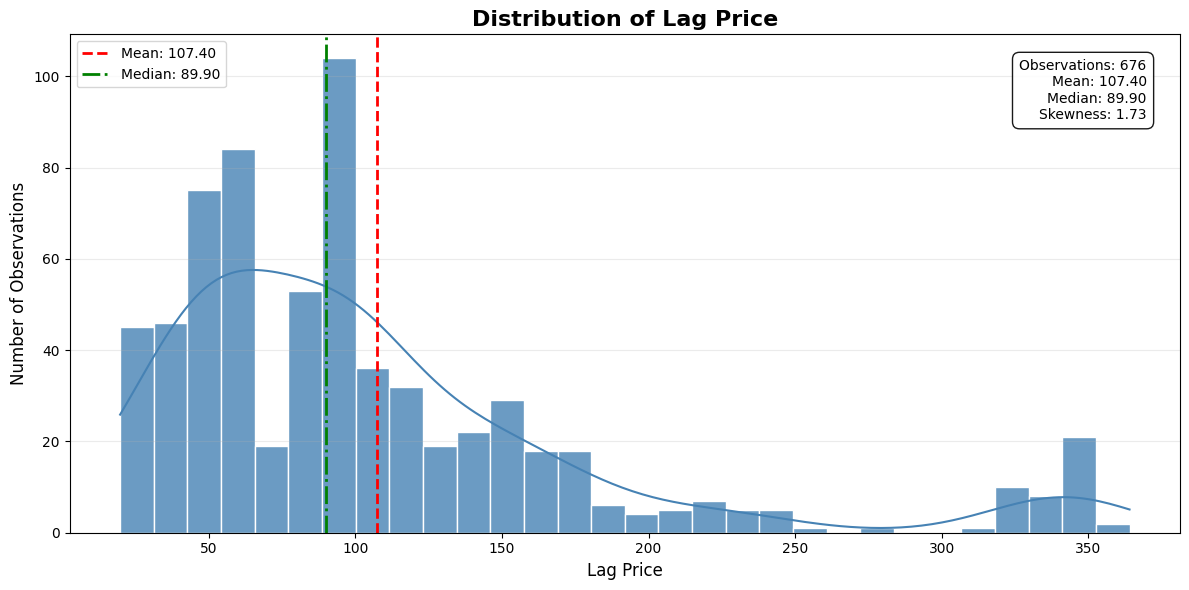

In [ ]:
# Visualize the distribution of the target variable

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

target = "lag_price"
data = df[target].dropna()

mean_val = data.mean()
median_val = data.median()
skew_val = data.skew()

plt.figure(figsize=(12, 6))

sns.histplot(
    data,
    bins=30,
    kde=True,
    color="steelblue",
    edgecolor="white",
    alpha=0.8
)

plt.axvline(
    mean_val,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_val:.2f}"
)

plt.axvline(
    median_val,
    color="green",
    linestyle="-.",
    linewidth=2,
    label=f"Median: {median_val:.2f}"
)

plt.title("Distribution of Lag Price", fontsize=16, fontweight="bold")
plt.xlabel("Lag Price", fontsize=12)
plt.ylabel("Number of Observations", fontsize=12)

plt.text(
    0.97, 0.95,
    f"Observations: {len(data)}\n"
    f"Mean: {mean_val:.2f}\n"
    f"Median: {median_val:.2f}\n"
    f"Skewness: {skew_val:.2f}",
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9)
)

plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

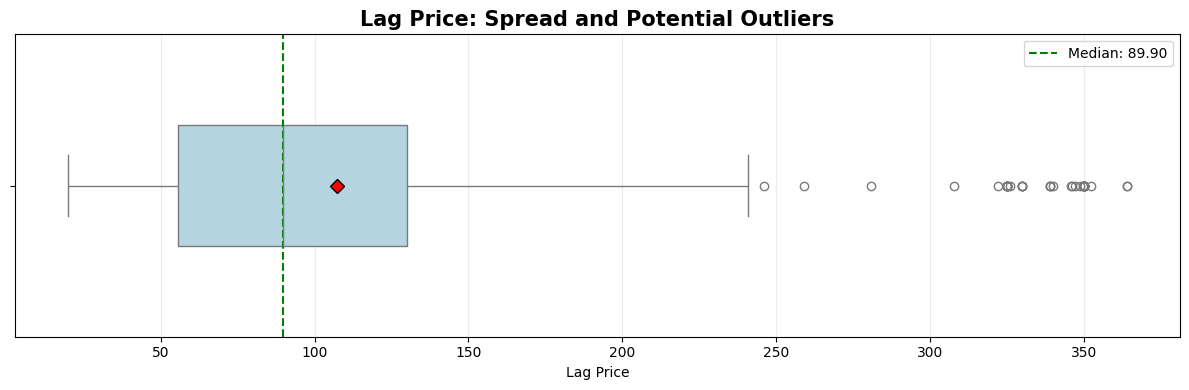

In [ ]:
# Visualize the spread and potential outliers of the target variable

plt.figure(figsize=(12, 4))

sns.boxplot(
    x=data,
    color="lightblue",
    width=0.4,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "black",
        "markersize": 7
    }
)

plt.axvline(
    median_val,
    color="green",
    linestyle="--",
    label=f"Median: {median_val:.2f}"
)

plt.title("Lag Price: Spread and Potential Outliers",
          fontsize=15, fontweight="bold")
plt.xlabel("Lag Price")
plt.grid(axis="x", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

In [37]:
# Calculate Quartiles and IQR

Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers = data[(data < lower_bound) | (data > upper_bound)]

print("Number of outliers:", len(outliers))
print("Percentage of outliers:", len(outliers) / len(data) * 100)

Q1: 55.66875
Q3: 129.99
IQR: 74.32125
Lower Bound: -55.813125
Upper Bound: 241.471875
Number of outliers: 45
Percentage of outliers: 6.656804733727811


In [41]:
# Identify and display the outliers

lag_outliers = data[data > upper_bound]

print(lag_outliers.sort_values(ascending=False))

483   364.0000
484   364.0000
482   352.2500
477   349.9000
480   349.9000
469   349.9000
468   349.9000
467   349.9000
471   349.9000
466   349.9000
475   349.9000
474   349.9000
479   349.9000
478   349.9000
481   349.9000
472   349.9000
473   349.9000
470   349.9000
465   349.8500
659   348.8000
661   347.0000
657   346.1580
658   345.7067
660   339.9000
656   339.0000
655   339.0000
654   338.9500
445   330.0000
442   330.0000
443   330.0000
444   330.0000
441   325.8929
438   325.0000
436   325.0000
435   325.0000
437   325.0000
434   325.0000
440   325.0000
439   325.0000
433   324.9500
476   322.1364
662   307.8333
663   280.6667
664   258.9696
665   245.9000
Name: lag_price, dtype: float64


In [40]:
outlier_rows = df[df['lag_price'] > upper_bound]

print(outlier_rows)

    product_id product_category_name  month_year  qty  total_price  \
433    health2         health_beauty  01-08-2017    6   1,950.0000   
434    health2         health_beauty  01-09-2017   11   3,575.0000   
435    health2         health_beauty  01-10-2017    2     650.0000   
436    health2         health_beauty  01-11-2017   12   3,900.0000   
437    health2         health_beauty  01-12-2017    6   1,950.0000   
438    health2         health_beauty  01-01-2018   10   3,250.0000   
439    health2         health_beauty  01-02-2018   23   7,475.0000   
440    health2         health_beauty  01-03-2018   28   9,125.0000   
441    health2         health_beauty  01-04-2018   21   6,930.0000   
442    health2         health_beauty  01-05-2018   19   6,270.0000   
443    health2         health_beauty  01-06-2018   16   5,280.0000   
444    health2         health_beauty  01-07-2018   13   4,290.0000   
445    health2         health_beauty  01-08-2018   28   9,240.0000   
465    health5      

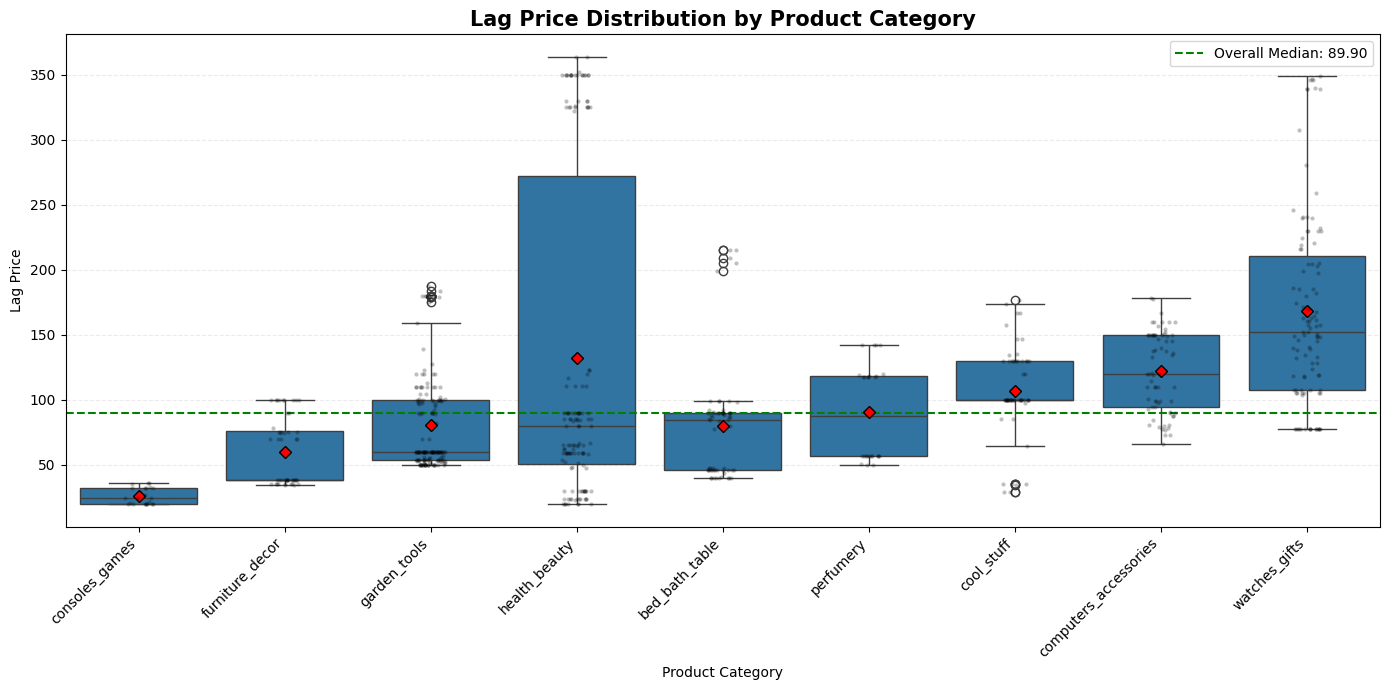

In [ ]:
# Analyze the target variable by product category

category_order = (
    df.groupby("product_category_name")[target]
      .median()
      .sort_values()
      .index
)

plt.figure(figsize=(14, 7))

# Boxplot
sns.boxplot(
    data=df,
    x="product_category_name",
    y=target,
    order=category_order,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "black",
        "markersize": 6
    }
)

# Individual observations
sns.stripplot(
    data=df,
    x="product_category_name",
    y=target,
    order=category_order,
    color="black",
    alpha=0.25,
    size=3,
    jitter=True
)

# Overall median
plt.axhline(
    df[target].median(),
    color="green",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall Median: {df[target].median():.2f}"
)

plt.title(
    "Lag Price Distribution by Product Category",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Product Category")
plt.ylabel("Lag Price")

plt.xticks(rotation=45, ha="right")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.legend()
plt.tight_layout()
plt.show()

In [47]:
# Analyze the target variable by product

product_target = (
    df.groupby("product_id")[target]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("mean", ascending=False)
)

display(product_target.head(20))


,count,mean,median,min,max
product_id,,,,,
health5,20,350.0368,349.9000,322.1364,364.0000
health2,13,326.6033,325.0000,324.9500,330.0000
watches7,12,319.8237,339.0000,245.9000,348.8000
watches5,10,216.9822,217.6238,203.2909,229.9000
bed5,5,208.6920,209.0000,199.5098,215.0000
watches8,10,191.6853,186.0591,145.1667,239.8500
watches1,17,182.0830,182.0000,132.5312,241.0060
garden8,14,175.8420,179.9400,139.0000,187.8543
cool4,9,156.2221,157.3604,134.9400,176.9900


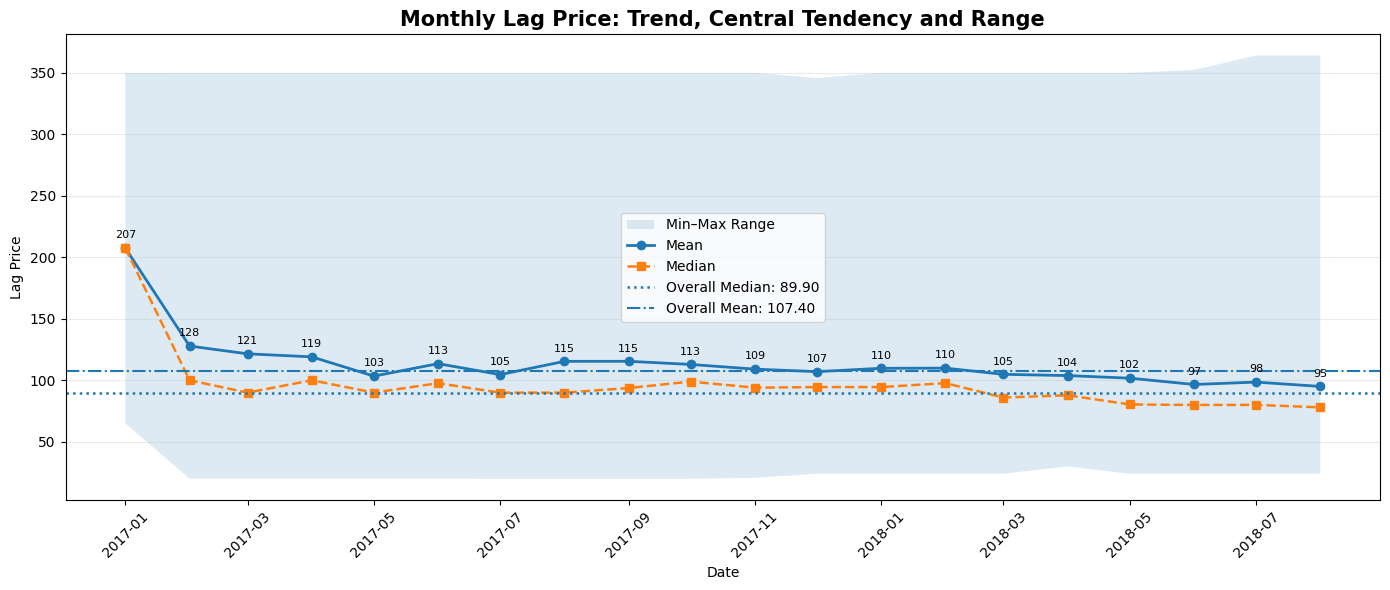

In [50]:
# Make sure date is datetime
df["date"] = pd.to_datetime(df["date"])

# Monthly target statistics
monthly_target = (
    df.groupby(df["date"].dt.to_period("M"))[target]
      .agg(["mean", "median", "min", "max"])
      .reset_index()
)

monthly_target["date"] = monthly_target["date"].dt.to_timestamp()

# Overall statistics
overall_median = df[target].median()
overall_mean = df[target].mean()

plt.figure(figsize=(14, 6))

# Min-Max range
plt.fill_between(
    monthly_target["date"],
    monthly_target["min"],
    monthly_target["max"],
    alpha=0.15,
    label="Min–Max Range"
)

# Mean
plt.plot(
    monthly_target["date"],
    monthly_target["mean"],
    marker="o",
    linewidth=2,
    label="Mean"
)

# Median
plt.plot(
    monthly_target["date"],
    monthly_target["median"],
    marker="s",
    linestyle="--",
    linewidth=1.8,
    label="Median"
)

# Overall median
plt.axhline(
    overall_median,
    linestyle=":",
    linewidth=1.8,
    label=f"Overall Median: {overall_median:.2f}"
)

# Overall mean
plt.axhline(
    overall_mean,
    linestyle="-.",
    linewidth=1.5,
    label=f"Overall Mean: {overall_mean:.2f}"
)

# Annotate mean values
for x, y in zip(monthly_target["date"], monthly_target["mean"]):
    plt.annotate(
        f"{y:.0f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 7),
        ha="center",
        fontsize=8
    )

plt.title(
    "Monthly Lag Price: Trend, Central Tendency and Range",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Lag Price")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.25)

plt.legend()
plt.tight_layout()
plt.show()

# PRICING ANALYSIS